In [ ]:
import time
from ugot import ugot
got=ugot.UGOT()
got.initialize('192.168.1.190')
got.play_audio_tts("Hello World.")
got.show_light_rgb_effect(0, 225,0,3)
time.sleep(2)
got.turn_off_lights()

In [9]:
# OpenCV libiary
import numpy as np
import cv2
from IPython.display import display, Image,clear_output
import matplotlib.pyplot as plt
import os

In [ ]:
pip show opencv-python

1. OpenCV and laptop camera

In [ ]:
import time
camera = cv2.VideoCapture(0, cv2.CAP_AVFOUNDATION)
time.sleep(1)

if camera.isOpened():
    frame_ok, frame = camera.read()

    if frame_ok:
        jpeg_ok, jpeg = cv2.imencode(".jpg", frame)

        if jpeg_ok:
            display(Image(data=jpeg.tobytes()))
else:
    print("The camera could not be opened.")

camera.release()

In [ ]:
# take five images,better version
import time
# open the laptop camera
camera = cv2.VideoCapture(0,cv2.CAP_AVFOUNDATION)  #Macbook
#Windows: camera = cv2.VideoCapture(0,cv2.CAP_DSHOW)
if not camera.isOpened():
    print("The camera is not opened.")
else:
    print("The camera is on")

    time.sleep(1)

    for i in range(5):
        frame_ok,frame = camera.read()
        if frame_ok:
            jpeg_ok,jpeg = cv2.imencode(".jpg",frame)
            if jpeg_ok:
                display(Image(data=jpeg.tobytes()))
                print(f"Picture{i+1}")
        time.sleep(1)

    camera.release()

3. live video with laptop camera

The camera is on


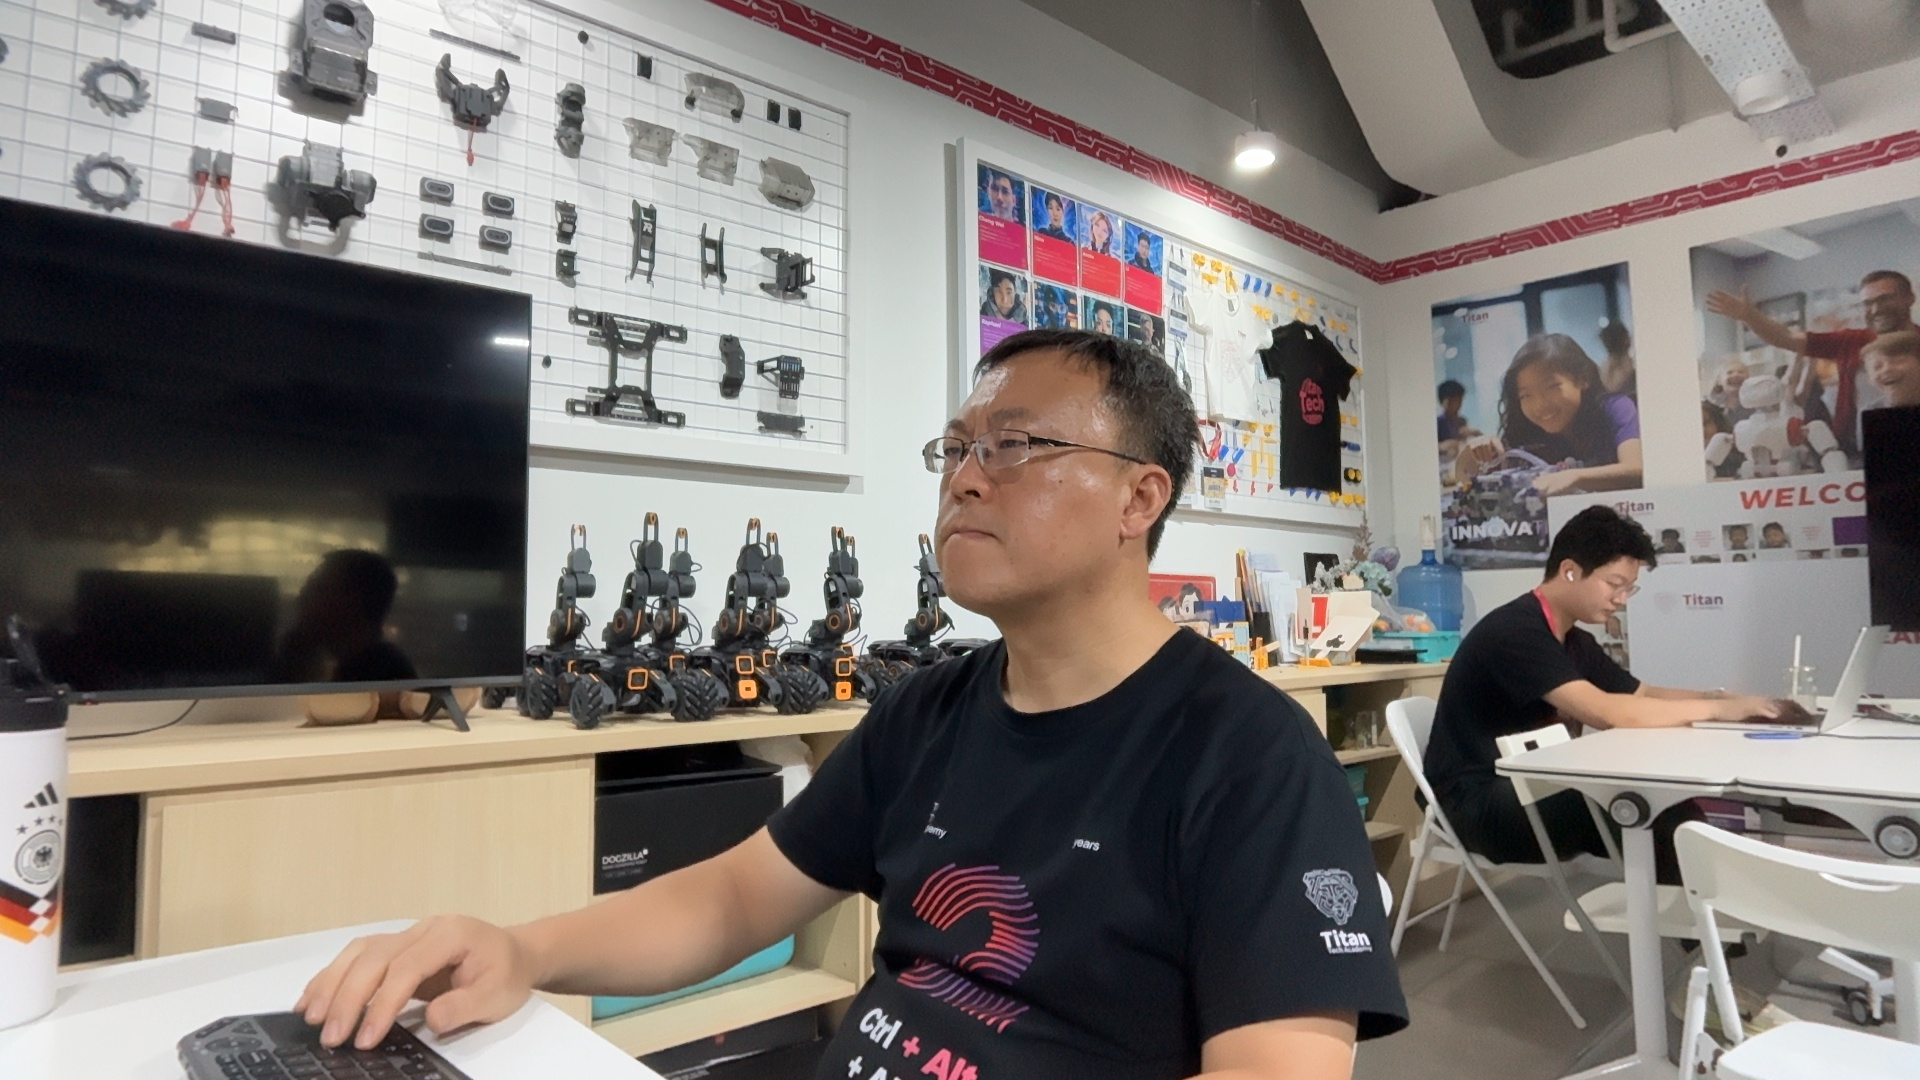

In [12]:
import time
# open the laptop camera
camera = cv2.VideoCapture(0,cv2.CAP_AVFOUNDATION)  #Macbook
#Windows: camera = cv2.VideoCapture(0,cv2.CAP_DSHOW)
if not camera.isOpened():
    print("The camera is not opened.")
else:
    print("The camera is on")

    time.sleep(1)

    handle = None
    start_time = time.time()

    while time.time()-start_time<5:
        frame_ok,frame = camera.read()
        if frame_ok:
            jpeg_ok,jpeg = cv2.imencode(".jpg",frame)
            if jpeg_ok:
                if handle is None: # create the display area for the first time
                    handle = display(Image(data=jpeg.tobytes()),display_id = True)
                else: # update the same display area
                    handle.update(Image(data=jpeg.tobytes()))
        time.sleep(0.02)

    camera.release()

4. image size

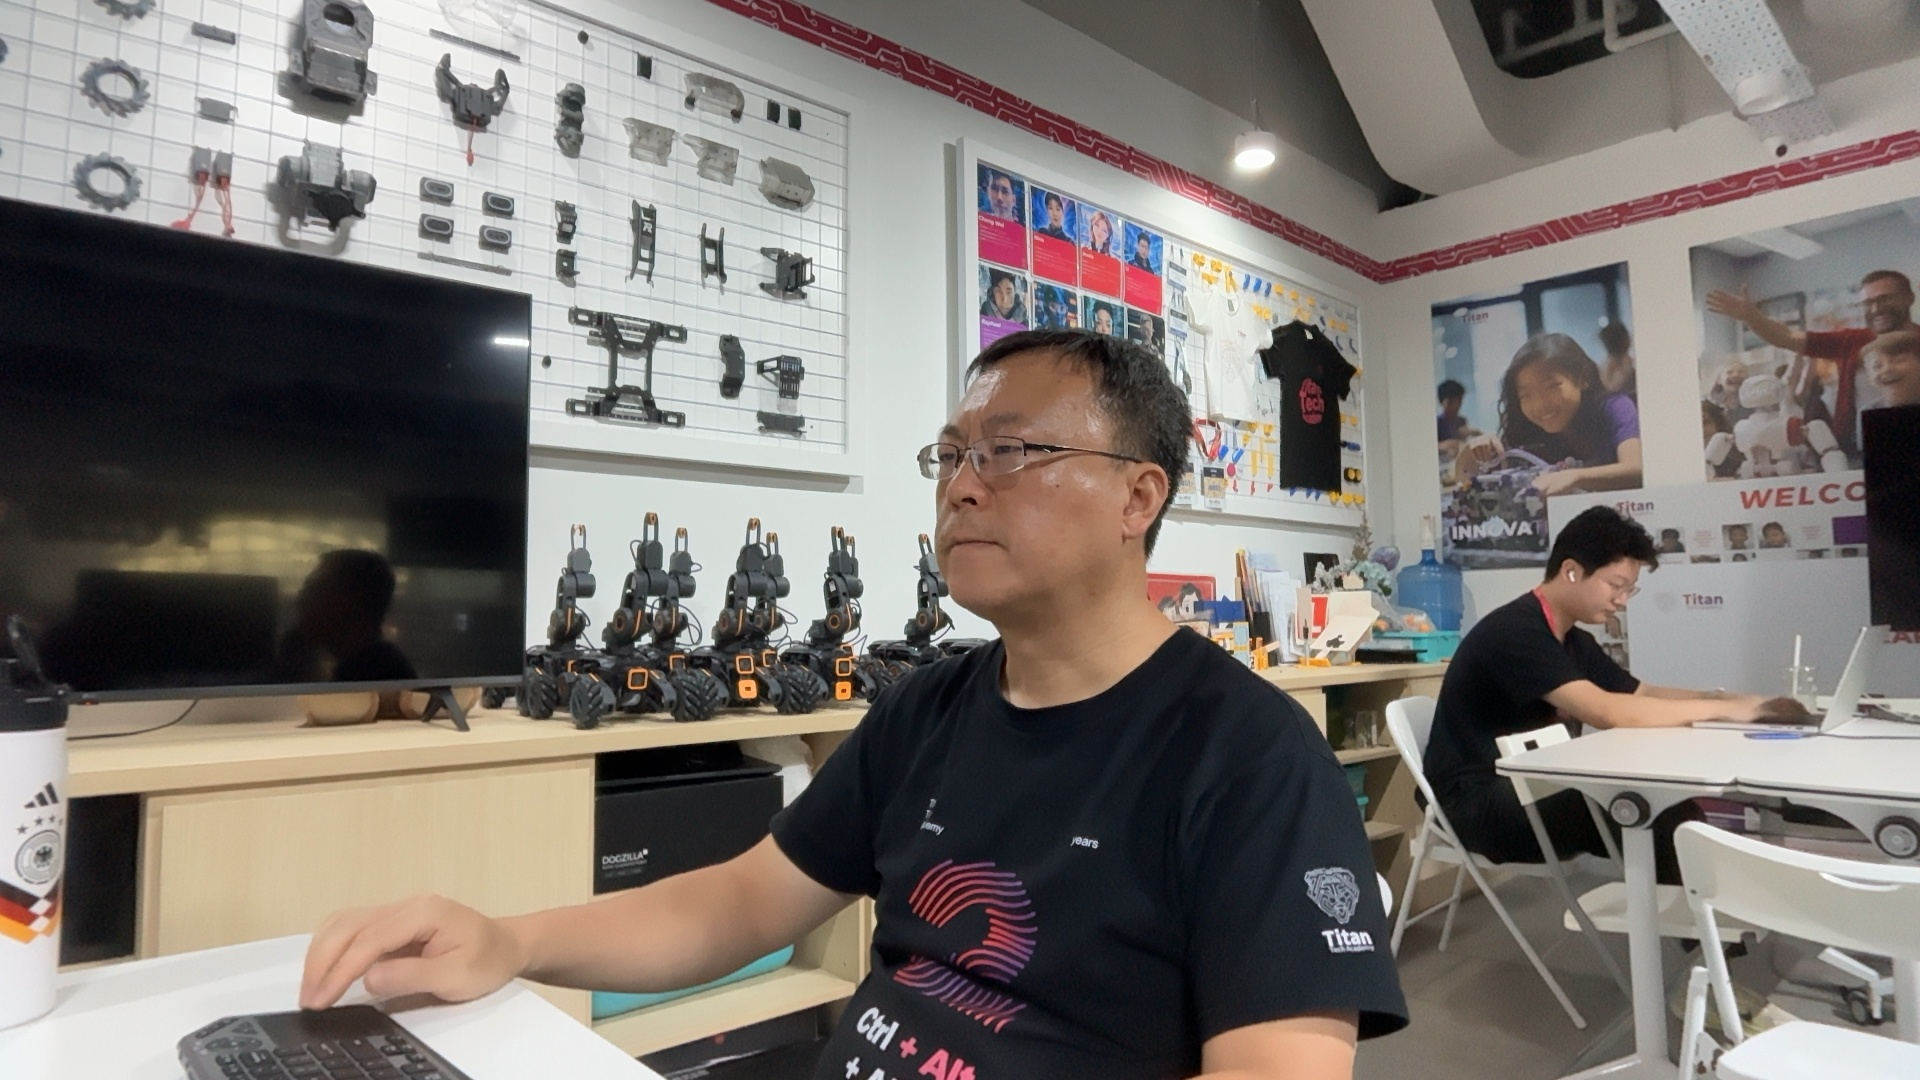

Full Shape: (1080, 1920, 3)
The height is:1080
The width is:1920 


In [13]:
import time
camera = cv2.VideoCapture(0, cv2.CAP_AVFOUNDATION)
time.sleep(1)

if camera.isOpened():
    frame_ok, frame = camera.read()
    if frame_ok:
        jpeg_ok, jpeg = cv2.imencode(".jpg", frame)
        if jpeg_ok:
            display(Image(data=jpeg.tobytes()))
            print(f"Full Shape: {frame.shape}")

            frame_height,frame_width = frame.shape[:2]
            print(f"The height is:{frame_height}")
            print(f"The width is:{frame_width} ")
else:
    print("The camera could not be opened.")

camera.release()

5.live video with a scanning box

The camera is on


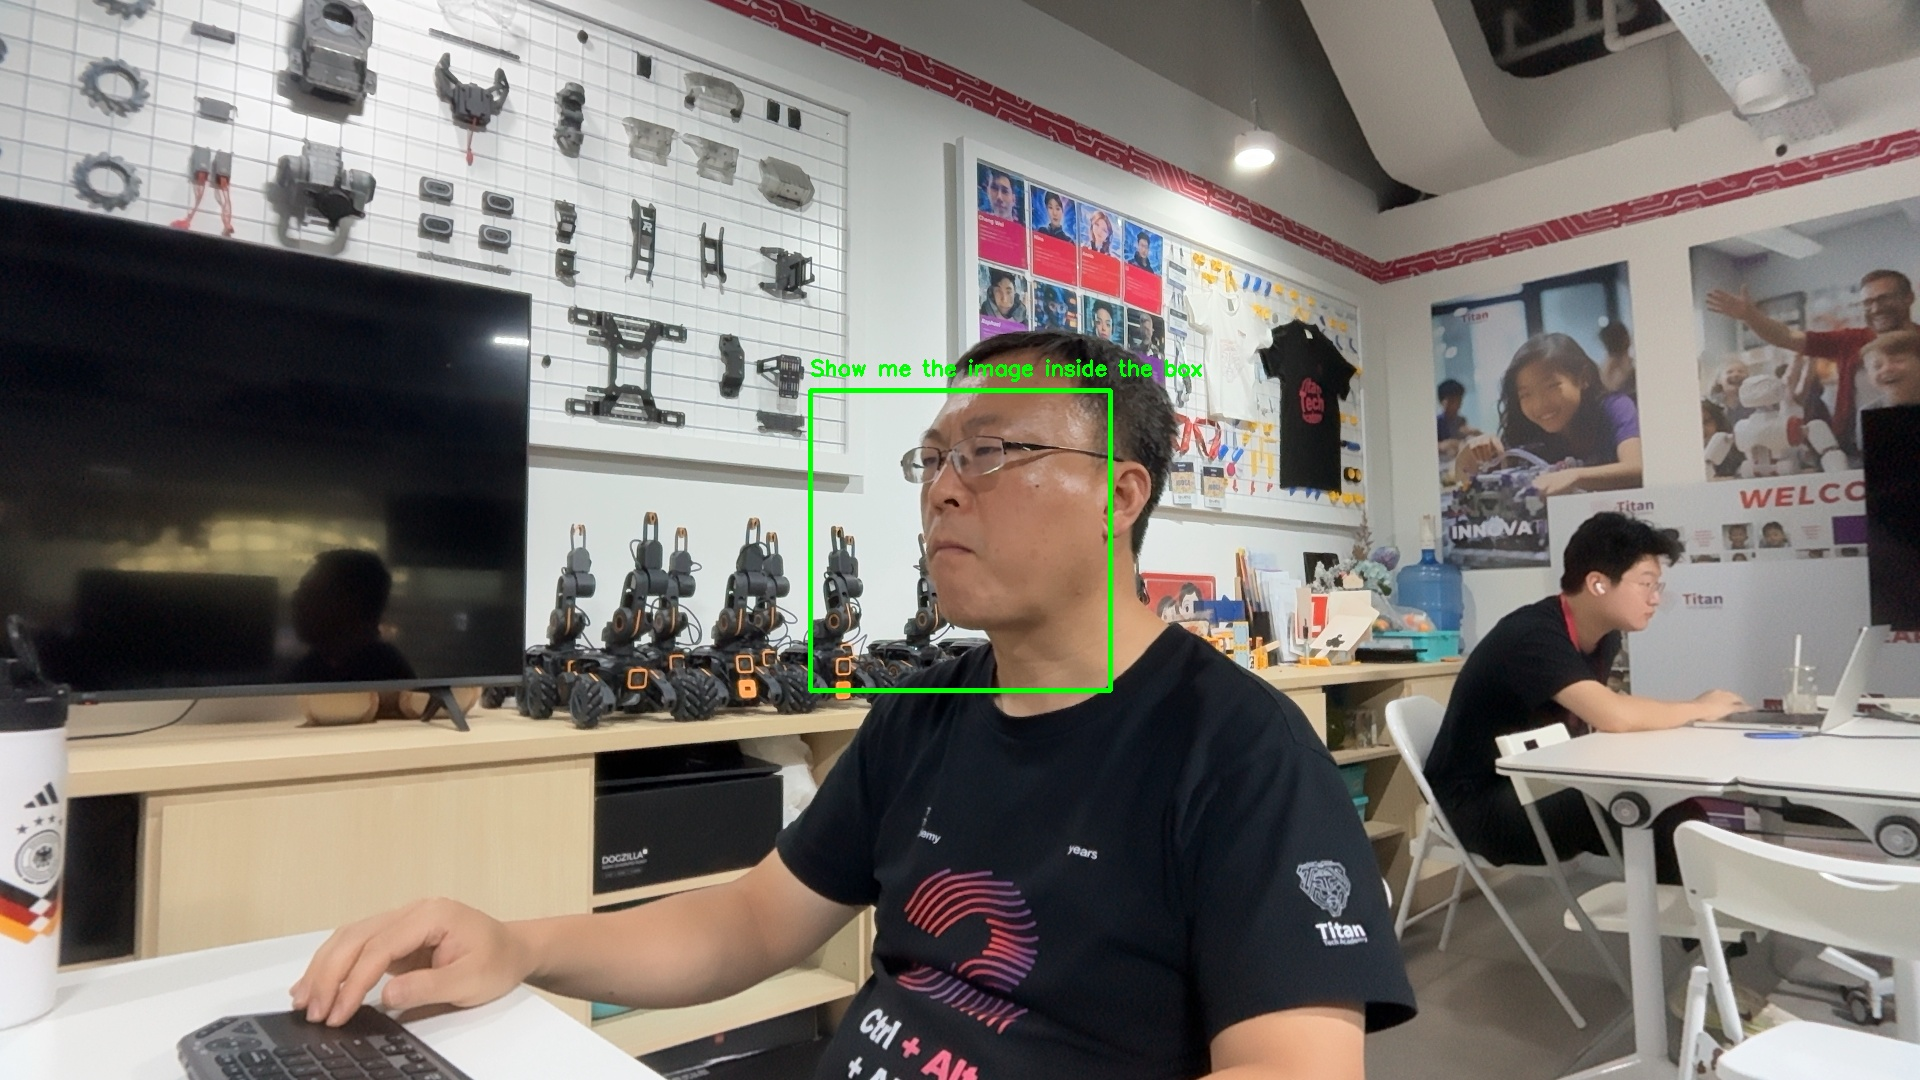

In [14]:
import time
# open the laptop camera
camera = cv2.VideoCapture(0,cv2.CAP_AVFOUNDATION)  #Macbook
#Windows: camera = cv2.VideoCapture(0,cv2.CAP_DSHOW)
if not camera.isOpened():
    print("The camera is not opened.")
else:
    print("The camera is on")

    time.sleep(1)

    handle = None
    start_time = time.time()

    while time.time()-start_time<10:
        frame_ok,frame = camera.read()
        if frame_ok:        
            # get the frame size
            frame_height,frame_width = frame.shape[:2]
            # set the scanning box size
            box_width = 300
            box_height = 300
            # calculate the top left corner
            x1 = (frame_width - box_width)//2
            y1 = (frame_height - box_height)//2
            # calculate the bottom right corner
            x2 = x1+box_width
            y2 = y1+box_height
            # draw a green scanning box
            cv2.rectangle(frame,(x1,y1),(x2,y2),(0,255,0),3)
            # add text above the box
            cv2.putText(frame,"Show me the image inside the box",
                        (x1,y1-15),cv2.FONT_HERSHEY_SIMPLEX,0.7,(0,255,0),2)
            
            jpeg_ok,jpeg = cv2.imencode(".jpg",frame)
            if jpeg_ok:
                if handle is None: # create the display area for the first time
                    handle = display(Image(data=jpeg.tobytes()),display_id = True)
                else: # update the same display area
                    handle.update(Image(data=jpeg.tobytes()))
        time.sleep(0.02)

    camera.release()

6. create folders to store the images

In [15]:
import os
# create main dataset folder
DATASET_FOLDER = "traffic_sign_dataset"
LEFT_FOLDER = os.path.join(DATASET_FOLDER,"LEFT")
RIGHT_FOLDER = os.path.join(DATASET_FOLDER,"RIGHT")
STOP_FOLDER = os.path.join(DATASET_FOLDER,"STOP")
NO_SIGN_FOLDER = os.path.join(DATASET_FOLDER,"NO_SIGN")

# create the real folder
os.makedirs(LEFT_FOLDER,exist_ok=True)
os.makedirs(RIGHT_FOLDER,exist_ok=True)
os.makedirs(STOP_FOLDER,exist_ok=True)
os.makedirs(NO_SIGN_FOLDER,exist_ok=True)

7. collect the images

In [ ]:
import time
import cv2
import os
from IPython.display import display, Image

# choose which category to collect
save_folder = LEFT_FOLDER
class_name = "LEFT"

total_images = 30
save_interval = 1

# open the laptop camera
camera = cv2.VideoCapture(0,cv2.CAP_AVFOUNDATION)  #Macbook
#Windows: camera = cv2.VideoCapture(0,cv2.CAP_DSHOW)
if not camera.isOpened():
    print("The camera is not opened.")
else:
    print(f"Collecting{class_name} images.")
    print("Place the sign inside the scanning box.")

    time.sleep(5)

    collected = 0
    last_save_time = 0
    handle = None

    while collected < total_images:
        frame_ok,frame = camera.read()
        if not frame_ok:
            print("The camera can not capture the image.")
            break

        # get the frame size
        frame_height,frame_width = frame.shape[:2]
        # set the scanning box size
        box_size = 300

        # calculate the top left corner
        x1 = (frame_width - box_size)//2
        y1 = (frame_height - box_size)//2
        # calculate the bottom right corner
        x2 = x1+box_size
        y2 = y1+box_size

        # crop the image inside the box
        scanning_area = frame[y1:y2,x1:x2]
        current_time = time.time()

        # save the image every 1 second
        if current_time- last_save_time >= save_interval:
            filename = os.path.join(save_folder,f"{class_name.lower()}_{collected}.jpg")
            save_ok = cv2.imwrite(filename,scanning_area)

            if save_ok:
                collected+=1
                last_save_time = current_time
                print(f"saved image{collected}")

        # draw a green scanning box
        cv2.rectangle(frame,(x1,y1),(x2,y2),(0,255,0),3)
        # show the numbers of collected images
        cv2.putText(frame,f"{class_name}:{collected}/{total_images}",
                        (x1,y1-15),cv2.FONT_HERSHEY_SIMPLEX,0.7,(0,255,0),2)
            
        jpeg_ok,jpeg = cv2.imencode(".jpg",frame)
        if jpeg_ok:
            if handle is None: # create the display area for the first time
                handle = display(Image(data=jpeg.tobytes()),display_id = True)
            else: # update the same display area
                handle.update(Image(data=jpeg.tobytes()))
    time.sleep(0.02)

    camera.release()
    print(f"Finished collecting {collected}{class_name} images.")

8. Image collection function

In [ ]:
import time
import cv2
import os
from IPython.display import display, Image

def collect_images(save_folder, class_name, total_images=30, save_interval=1):
    # make the folder if it does not exist yet
    os.makedirs(save_folder, exist_ok=True)

    camera = cv2.VideoCapture(0, cv2.CAP_AVFOUNDATION)   # Macbook
    # Windows: camera = cv2.VideoCapture(0, cv2.CAP_DSHOW)

    if not camera.isOpened():
        print("The camera is not opened.")
        return 0

    print(f"Collecting {class_name} images.")
    print("Place the sign inside the scanning box.")
    time.sleep(5)

    collected = 0
    last_save_time = 0
    handle = None

    while collected < total_images:
        frame_ok, frame = camera.read()
        if not frame_ok:
            print("The camera can not capture the image.")
            break

        frame_height, frame_width = frame.shape[:2]
        box_size = 300

        x1 = (frame_width - box_size)//2
        y1 = (frame_height - box_size)//2
        x2 = x1 + box_size
        y2 = y1 + box_size

        # crop the clean frame BEFORE drawing anything
        scanning_area = frame[y1:y2, x1:x2]
        current_time = time.time()

        if current_time - last_save_time >= save_interval:
            filename = os.path.join(save_folder, f"{class_name.lower()}_{collected}.jpg")
            save_ok = cv2.imwrite(filename, scanning_area)
            if save_ok:
                collected += 1
                last_save_time = current_time
                print(f"saved image {collected}")

        cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 255, 0), 3)
        cv2.putText(frame, f"{class_name}:{collected}/{total_images}",
                    (x1, y1-15), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)

        jpeg_ok, jpeg = cv2.imencode(".jpg", frame)
        if jpeg_ok:
            if handle is None:
                handle = display(Image(data=jpeg.tobytes()), display_id=True)
            else:
                handle.update(Image(data=jpeg.tobytes()))

        time.sleep(0.02)

    camera.release()
    print(f"Finished collecting {collected} {class_name} images.")
    return collected

In [ ]:
collect_images(RIGHT_FOLDER, "RIGHT", total_images=30, save_interval=1)

In [ ]:
collect_images(NO_SIGN_FOLDER, "NO_SIGN", total_images=30, save_interval=1)

In [ ]:
collect_images(STOP_FOLDER, "STOP", total_images=30, save_interval=1)

9. check the dataset

In [ ]:
import glob
left_images = glob.glob(LEFT_FOLDER+"/*.jpg")
right_images = glob.glob(RIGHT_FOLDER+"/*.jpg")
stop_images = glob.glob(STOP_FOLDER+"/*.jpg")
no_sign_images = glob.glob(NO_SIGN_FOLDER+"/*.jpg")

print(f"LEFT: {len(left_images)}")
print(f"RIGHT: {len(right_images)}")
print(f"STOP: {len(stop_images)}")
print(f"NO_SIGN: {len(no_sign_images)}")

10.training data preparation

In [ ]:
mininum_images = 28
dataset_ready = True

if len(left_images) < mininum_images:
    print("LEFT needs more images.")
    dataset_ready = False
if len(right_images) < mininum_images:
    print("RIGHT needs more images.")
    dataset_ready = False
if len(stop_images) < mininum_images:
    print("STOP needs more images.")
    dataset_ready = False
if len(no_sign_images) < mininum_images:
    print("NO SIGN needs more images.")
    dataset_ready = False

if dataset_ready:
    print("The dataset is ready for training.")
else:
    print("Please collect more images.")

11. turn one image into KNN number

In [ ]:
import numpy as np
import cv2
from IPython.display import display, Image
import matplotlib.pyplot as plt
import os
import time
import glob

# Define the image size for KNN
IMAGE_SIZE = 32
# choose the KNN neighbours
k = 3
BOX_SIZE = 300

def prepare_image(image):
    #step1: change the image to grayscale
    gray = cv2.cvtColor(image,cv2.COLOR_BGR2GRAY)
    #step2: make every image 32*32
    small_image = cv2.resize(gray,(IMAGE_SIZE,IMAGE_SIZE))
    #step3: change the square into one long row
    pixel_row = small_image.flatten()
    #step4: change the long row to float32
    pixel_row = pixel_row.astype(np.float32)
    #step5: change 0-255 into 0-1
    pixel_row = pixel_row/255.0
    return pixel_row

print(f"prepare_image is ready, every picture will become {IMAGE_SIZE * IMAGE_SIZE} numbers.")

12. load the training images

In [ ]:
if not dataset_ready:
    print("The dataset is not ready.")
else:
    training_data = []
    training_labels =[]

    #LEFT = 0
    for filename in glob.glob(os.path.join(LEFT_FOLDER,"*.jpg")):
        image = cv2.imread(filename)

        if image is not None:
            training_data.append(prepare_image(image))
            training_labels.append(0)
   #RIGHT = 1
    for filename in glob.glob(os.path.join(RIGHT_FOLDER,"*.jpg")):
        image = cv2.imread(filename)
   
        if image is not None:
            training_data.append(prepare_image(image))
            training_labels.append(1) 
    #STOP = 2
    for filename in glob.glob(os.path.join(STOP_FOLDER,"*.jpg")):
        image = cv2.imread(filename)

        if image is not None:
            training_data.append(prepare_image(image))
            training_labels.append(2)
    #NO_SIGN = 3
    for filename in glob.glob(os.path.join(NO_SIGN_FOLDER,"*.jpg")):
        image = cv2.imread(filename)

        if image is not None:
            training_data.append(prepare_image(image))
            training_labels.append(3)
    # change the Python list into Numpy arrays for OpenCV
    training_data = np.array(training_data,dtype=np.float32)
    training_labels=np.array(training_labels,dtype=np.float32).reshape(-1,1)

    print(f"Training data shape: {training_data.shape}")
    print(f"Training labels shape: {training_labels.shape}")

13. train KNN model

In [ ]:
knn = cv2.ml.KNearest_create()

knn.train(training_data,cv2.ml.ROW_SAMPLE,training_labels)

print("KNN training is complete.")

14. predicit one image

In [ ]:
def predict_sign(image):
    pixel_row = prepare_image(image)

    #OpenCV wants one sample row
    pixel_row =pixel_row.reshape(1,-1)
    _,result,neighbours,distance = knn.findNearest(pixel_row,k)

    label = int(result[0][0])

    if label == 0:
        prediction = "LEFT"
    elif label == 1:
        prediction = "RIGHT"
    elif label == 2:
        prediction = "STOP"
    else:
        prediction = "NO_SIGN"
    return prediction

print("prediction_sign is ready.")

15. KNN test without UGOT

In [ ]:
import time
camera = cv2.VideoCapture(0)
if not camera.isOpened():
    raise Exception("Cannot open the laptop camera.")
print("The camera is open.")

ok,picture_bgr = camera.read()
if not ok:
    raise Exception("No camera data.")

ok,picture_jpg = cv2.imencode(".jpg",picture_bgr)
handle = display(Image(data=picture_jpg.tobytes()), display_id=True)

start_time = time.time()
duration = 40

while time.time()-start_time< duration:
    ok,picture_bgr = camera.read()
    if not ok:
        continue

    BOX_SIZE = 300
    height,width = picture_bgr.shape[:2]
    x1 = width//2 - BOX_SIZE//2
    y1 = height//2 - BOX_SIZE//2
    x2 = x1+BOX_SIZE
    y2 = y1+BOX_SIZE

    crop = picture_bgr[y1:y2,x1:x2]
    prediction = predict_sign(crop)

    cv2.rectangle(picture_bgr,(x1,y1),(x2,y2),(0,255,0),3)
    cv2.putText(picture_bgr,prediction,(x1,y1-15),cv2.FONT_HERSHEY_SIMPLEX,0.7,(0,255,0),2)

    ok,picture_jpg = cv2.imencode(".jpg",picture_bgr)
    if ok:
        handle.update(Image(data=picture_jpg.tobytes()))

    time.sleep(0.1)

camera.release()
print("Test finished.")

16. UGOT control with KNN

In [ ]:
# time limits

camera = cv2.VideoCapture(0)
if not camera.isOpened():
    raise Exception("Cannot open the laptop camera.")
print("The camera is on.")

ok, picture_bgr = camera.read()
if not ok:
    raise Exception("No camera data.")

ok, picture_jpg = cv2.imencode(".jpg", picture_bgr)
handle = display(Image(picture_jpg.tobytes()), display_id=True)

forward_speed = 15      # cm/s
turn_speed = 30          # deg/s
CONFIRM_FRAMES = 3       # require the same prediction this many times in a row

last_prediction = "NO_SIGN"
confirm_count = 0

start_time = time.time()
duration = 60

while time.time() - start_time < duration:
    ok, picture_bgr = camera.read()
    if not ok:
        continue

    # picture_bgr = cv2.flip(picture_bgr, 1)

    height, width = picture_bgr.shape[:2]
    x1 = width//2 - BOX_SIZE//2
    y1 = height//2 - BOX_SIZE//2
    x2 = x1 + BOX_SIZE
    y2 = y1 + BOX_SIZE

    crop = picture_bgr[y1:y2,x1:x2]
    prediction = predict_sign(crop)

    cv2.rectangle(picture_bgr, (x1,y1), (x2,y2), (0,255,0), 2)
    cv2.putText(picture_bgr, prediction, (x1,y1-10), cv2.FONT_HERSHEY_SIMPLEX, 1, (0,255,0), 2)

    # debounce: only act once the same prediction repeats
    if prediction == last_prediction:
        confirm_count += 1
    else:
        confirm_count = 1
        last_prediction = prediction

    if confirm_count == CONFIRM_FRAMES:
        if prediction == "NO_SIGN":
            got.mecanum_move_speed(0, forward_speed)
            got.play_audio_tts("I am moving forward.",1,False)
        elif prediction == "LEFT":
            got.mecanum_stop()
            got.mecanum_turn_speed(2, turn_speed)
            got.play_audio_tts("I am turning left.",1,False)
        elif prediction == "RIGHT":
            got.mecanum_stop()
            got.mecanum_turn_speed(3, turn_speed)
            got.play_audio_tts("I am turning right.",1,False)
        elif prediction == "STOP":
            got.mecanum_stop()
            got.play_audio_tts("I will stop moving.",1,False)

    ok, picture_jpg = cv2.imencode(".jpg", picture_bgr)
    if ok:
        handle.update(Image(picture_jpg.tobytes()))

    time.sleep(0.1)

got.mecanum_stop()
camera.release()
print("Test finished.")